# Validação das métricas de futebol — parte 2

Prévia dos cálculos e de um gráfico, conforme o slide 15. Lê o CSV tratado, sem refazer ou modificar a EDA original. A temporada mais recente é usada como recorte reproduzível; no aplicativo, os filtros recalculam esses resultados.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "data/clean/futebol.csv").is_file())
sys.path.insert(0, str(RAIZ))
from src.metricas import calcular_metricas, top_jogadores

df = pd.read_csv(RAIZ / "data/clean/futebol.csv")
temporada = int(df["season"].max())
recorte = df[df["season"].eq(temporada)].copy()
print("Base tratada:", df.shape)
print("Temporada:", temporada, "| Registros do recorte:", len(recorte))

Base tratada: (22414, 181)
Temporada: 2425 | Registros do recorte: 2852


## Cálculo direto das quatro métricas

A proporção usa a razão das somas e as mesmas linhas válidas no numerador e no denominador. Ausência não significa zero. As contagens são totais do recorte, não taxas por minuto ou por partida.

In [2]:
pares = recorte[["Standard_Sh", "Standard_SoT"]].dropna()
pares = pares[(pares.Standard_Sh >= 0) & (pares.Standard_SoT >= 0)
              & (pares.Standard_SoT <= pares.Standard_Sh)]
chutes = pares.Standard_Sh.sum()
alvo = pares.Standard_SoT.sum()
pontaria = 100 * alvo / chutes if chutes > 0 else None

direto = {
    "pontaria": pontaria,
    "gols": recorte.Performance_Gls.sum(min_count=1),
    "amarelos": recorte.Performance_CrdY.sum(min_count=1),
    "vermelhos": recorte.Performance_CrdR.sum(min_count=1),
}
calculado = calcular_metricas(recorte)
for nome, esperado in direto.items():
    assert np.isclose(calculado[nome], esperado), nome

display(pd.DataFrame({"Métrica": list(direto), "Valor": list(direto.values())}))
print("Base da pontaria:", len(pares), "linhas |", alvo, "no alvo /", chutes, "chutes")
print("Validação dos quatro cálculos: OK")

,Métrica,Valor
0,pontaria,33.398184
1,gols,4805.000000
2,amarelos,7134.000000
3,vermelhos,328.000000


Base da pontaria: 2852 linhas | 14420 no alvo / 43176.0 chutes
Validação dos quatro cálculos: OK


## Rankings e transferências

Agrupamos nome e ano de nascimento antes de ordenar. Assim, um jogador transferido mantém seu total dentro das ligas e clubes do recorte. Nomes iguais com anos diferentes não são somados. Os três rankings são independentes.

In [3]:
campos = {"gols": "Performance_Gls", "amarelos": "Performance_CrdY", "vermelhos": "Performance_CrdR"}
for nome, campo in campos.items():
    agregado = recorte.groupby(["player", "born_"], dropna=False)[campo].sum(min_count=1).reset_index()
    esperado = (agregado[agregado[campo] > 0]
                .sort_values([campo, "player", "born_"], ascending=[False, True, True], kind="stable")
                .head(5).reset_index(drop=True))
    obtido = top_jogadores(recorte, nome)
    pd.testing.assert_frame_equal(obtido[["player", "born_", campo]], esperado[["player", "born_", campo]])
    print("Top 5:", nome)
    display(obtido[["rotulo", campo]])
print("Validação dos rankings: OK")

Top 5: gols


,rotulo,Performance_Gls
0,Kylian Mbappé,31
1,Mohamed Salah,29
2,Robert Lewandowski,27
3,Harry Kane,26
4,Mateo Retegui,25


Top 5: amarelos


,rotulo,Performance_CrdY
0,Facundo Medina,15
1,Yvan Neyou,14
2,Abdel Abqar,13
3,Jaka Bijol,13
4,Nicolò Rovella,13


Top 5: vermelhos


,rotulo,Performance_CrdR
0,Mario Martín,3
1,Alessio Romagnoli,2
2,Ante Rebić,2
3,Bruno Fernandes,2
4,Christantus Uche,2


Validação dos rankings: OK


## Gráfico prévio: gols agrupados por jogador

Esta prévia valida a ideia de gráfico de barras. A aplicação usa Altair para oferecer tooltip e seleção. O preenchimento das chuteiras é relativo ao líder do ranking, não uma porcentagem de pontaria.

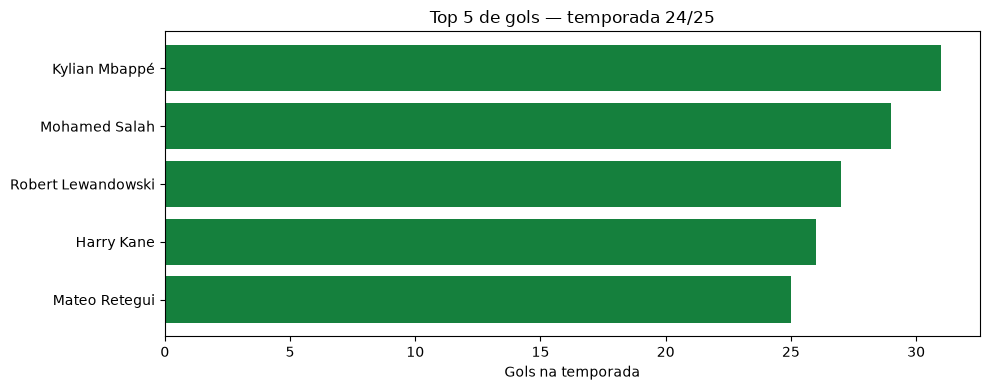

In [4]:
ranking = top_jogadores(recorte, "gols")
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(ranking["rotulo"], ranking["Performance_Gls"], color="#15803d")
ax.invert_yaxis()
ax.set_xlabel("Gols na temporada")
ax.set_title(f"Top 5 de gols — temporada {str(temporada)[:2]}/{str(temporada)[2:]}")
fig.tight_layout()
plt.show()

## Resultado da validação

As quatro métricas e os rankings foram comparados com cálculos diretos em pandas. Este notebook não avalia quem é o “melhor” jogador: totais dependem também de minutos, posição e oportunidades. Antes de interpretar uma proporção, consulte a quantidade de chutes que forma sua base. Os testes de situações de borda ficam em `tests/`.